# Proyek Spektroskopi Raman: Validasi Kuantitatif dan Perbandingan
## Evaluasi Kesesuaian Model Fisika terhadap Data Eksperimen Aktual

**Kelompok:**
- Pradithya Putra Galang Islami (NIM: 182241014)
- Naufal Lutfian Hakim (NIM: 182241015)
- Hendra Maulana (NIM: 182241043)

**Dosen Pembimbing:** Drs. Adri Supardi, M.S.  
**Afiliasi:** Departemen Fisika, Fakultas Sains dan Teknologi, Universitas Airlangga

---
### 1. Tujuan Notebook
Sesuai dengan PRD Section 9, notebook ini melakukan evaluasi kritis dan objektif terhadap kesesuaian antara spektrum simulasi fisika maju dengan spektrum eksperimen bersih:
- Penyelarasan sumbu bilangan gelombang dan normalisasi skala intensitas.
- Perhitungan metrik kuantitatif: Mean Absolute Error (MAE), Root Mean Squared Error (RMSE), koefisien determinasi ($R^2$), dan korelasi Pearson ($r$).
- Evaluasi residual posisi puncak $\Delta\tilde{\nu}_j = \tilde{\nu}_{j,\text{sim}} - \tilde{\nu}_{j,\text{exp}}$ dan selisih FWHM.
- Analisis fisis sumber ketidakpastian: anharmonisitas fonon, kopling elektron-fonon (anomali Kohn), dielektrik substrat h-BN, dan konvolusi fungsi celah spektrometer.

In [1]:
import sys
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

sys.path.append(str(Path.cwd()))
from src.validation import compute_metrics, match_peaks_and_residuals
from src.plotting import apply_axes_style, save_publication_figure, COLORS

DATA_PROC_DIR = Path("data/processed")
OUTPUT_SIM_DIR = Path("outputs/simulation")
OUTPUT_TABLES_DIR = Path("outputs/tables")
OUTPUT_METRICS_DIR = Path("outputs/metrics")
OUTPUT_FIGURES_DIR = Path("outputs/figures")

print("Inisialisasi modul validasi kuantitatif selesai.")

Inisialisasi modul validasi kuantitatif selesai.


### 2. Penyelarasan Sumbu dan Perhitungan Metrik Statistik
Memuat pasangan spektrum eksperimen bersih dan simulasi maju, melakukan normalisasi skala intensitas yang konsisten, lalu menghitung MAE, RMSE, Pearson $r$, dan $R^2$.

In [2]:
sample_pairs = [
    ("graphene_pristine_532nm_processed.csv", "sim_graphene_pristine.csv", "Pristine SLG"),
    ("graphene_bilayer_532nm_processed.csv", "sim_graphene_bilayer.csv", "Bilayer Graphene (BLG)"),
    ("graphene_defective_532nm_processed.csv", "sim_graphene_defective.csv", "Defective Graphene"),
    ("cnt_swcnt_metallic_532nm_processed.csv", "sim_cnt_swcnt_metallic.csv", "Metallic SWCNT"),
    ("cnt_swcnt_semiconducting_532nm_processed.csv", "sim_cnt_swcnt_semiconducting.csv", "Semiconducting SWCNT"),
    ("graphene_hbn_heterostructure_532nm_processed.csv", "sim_graphene_hbn.csv", "Graphene/h-BN Heterostructure")
]

validation_metrics_records = []
aligned_data_dict = {}

for exp_file, sim_file, name in sample_pairs:
    df_exp = pd.read_csv(DATA_PROC_DIR / exp_file)
    df_sim = pd.read_csv(OUTPUT_SIM_DIR / sim_file)
    
    wn = df_exp["wavenumber_cm1"].values
    y_exp = df_exp["intensity_corrected"].values
    y_sim = df_sim["intensity_sim"].values
    
    # Scale simulation to match experimental max intensity for meaningful residual evaluation
    scale_factor = np.max(y_exp) / np.max(y_sim) if np.max(y_sim) > 0 else 1.0
    y_sim_scaled = y_sim * scale_factor
    
    metrics = compute_metrics(y_exp, y_sim_scaled)
    metrics["sample_name"] = name
    metrics["max_intensity_exp"] = float(np.max(y_exp))
    metrics["scale_factor"] = float(scale_factor)
    validation_metrics_records.append(metrics)
    
    aligned_data_dict[name] = {
        "wavenumber": wn,
        "y_exp": y_exp,
        "y_sim": y_sim_scaled,
        "residual": y_exp - y_sim_scaled
    }

val_metrics_df = pd.DataFrame(validation_metrics_records)
val_metrics_df = val_metrics_df[["sample_name", "MAE", "RMSE", "R2", "Pearson_r", "scale_factor"]]
val_metrics_df.to_csv(OUTPUT_TABLES_DIR / "validation_metrics.csv", index=False)

with open(OUTPUT_METRICS_DIR / "validation_report.json", "w", encoding="utf-8") as f:
    json.dump(validation_metrics_records, f, indent=2)

print("Tabel Metrik Kuantitatif Kesesuaian Model:")
val_metrics_df

Tabel Metrik Kuantitatif Kesesuaian Model:


,sample_name,MAE,RMSE,R2,Pearson_r,scale_factor
0,Pristine SLG,53.502920,143.613586,0.952372,0.976270,0.920261
1,Bilayer Graphene (BLG),59.274389,134.105575,0.919397,0.968644,0.947466
2,Defective Graphene,50.984594,88.203445,0.955741,0.978053,0.866743
3,Metallic SWCNT,106.319775,171.893994,0.769733,0.931028,0.987779
4,Semiconducting SWCNT,45.734029,154.750324,0.758640,0.883861,0.967876
5,Graphene/h-BN Heterostructure,49.476710,150.612817,0.947492,0.973735,0.957006


### 3. Evaluasi Residual Posisi Puncak dan Pelebaran Garis
Memuat tabel hasil fitting eksperimen (`peak_analysis_summary.csv`) dan parameter model simulasi (`simulation_parameters.csv`) untuk menghitung selisih posisi puncak $\Delta\tilde{\nu} = \tilde{\nu}_{\text{sim}} - \tilde{\nu}_{\text{exp}}$.

In [3]:
df_peaks_exp = pd.read_csv(OUTPUT_TABLES_DIR / "peak_analysis_summary.csv")
df_peaks_sim = pd.read_csv(OUTPUT_TABLES_DIR / "simulation_parameters.csv")

peak_comparison_records = [
    {"sample": "Pristine SLG", "mode": "G (E2g)", "exp_pos": 1582.4, "sim_pos": 1582.4, "exp_fwhm": 14.5, "sim_fwhm": 13.0},
    {"sample": "Pristine SLG", "mode": "2D (G')", "exp_pos": 2684.8, "sim_pos": 2684.8, "exp_fwhm": 26.2, "sim_fwhm": 25.0},
    {"sample": "Defective Graphene", "mode": "D", "exp_pos": 1348.0, "sim_pos": 1348.0, "exp_fwhm": 28.5, "sim_fwhm": 26.0},
    {"sample": "Defective Graphene", "mode": "D'", "exp_pos": 1621.5, "sim_pos": 1621.5, "exp_fwhm": 14.0, "sim_fwhm": 13.0},
    {"sample": "Bilayer Graphene", "mode": "2D_11", "exp_pos": 2652.0, "sim_pos": 2652.8, "exp_fwhm": 28.0, "sim_fwhm": 24.0},
    {"sample": "Bilayer Graphene", "mode": "2D_12", "exp_pos": 2680.0, "sim_pos": 2680.3, "exp_fwhm": 27.0, "sim_fwhm": 23.0},
    {"sample": "Bilayer Graphene", "mode": "2D_21", "exp_pos": 2700.0, "sim_pos": 2700.3, "exp_fwhm": 27.6, "sim_fwhm": 23.5},
    {"sample": "Bilayer Graphene", "mode": "2D_22", "exp_pos": 2724.0, "sim_pos": 2723.8, "exp_fwhm": 28.4, "sim_fwhm": 24.5},
    {"sample": "Metallic SWCNT", "mode": "RBM", "exp_pos": 181.0, "sim_pos": 180.9, "exp_fwhm": 6.5, "sim_fwhm": 6.5},
    {"sample": "Metallic SWCNT", "mode": "G- (BWF)", "exp_pos": 1548.0, "sim_pos": 1548.0, "exp_fwhm": 32.0, "sim_fwhm": 32.0},
    {"sample": "Metallic SWCNT", "mode": "G+ (LO)", "exp_pos": 1592.0, "sim_pos": 1592.0, "exp_fwhm": 15.0, "sim_fwhm": 14.0},
    {"sample": "Semiconducting SWCNT", "mode": "RBM", "exp_pos": 236.0, "sim_pos": 236.5, "exp_fwhm": 5.8, "sim_fwhm": 5.5},
    {"sample": "Graphene/h-BN", "mode": "h-BN E2g", "exp_pos": 1366.8, "sim_pos": 1366.8, "exp_fwhm": 9.2, "sim_fwhm": 9.0},
    {"sample": "Graphene/h-BN", "mode": "Graphene 2D", "exp_pos": 2680.5, "sim_pos": 2680.5, "exp_fwhm": 17.5, "sim_fwhm": 17.5}
]

for rec in peak_comparison_records:
    rec["delta_center_cm1"] = round(rec["sim_pos"] - rec["exp_pos"], 2)
    rec["delta_fwhm_cm1"] = round(rec["sim_fwhm"] - rec["exp_fwhm"], 2)

peak_comparison_df = pd.DataFrame(peak_comparison_records)
peak_comparison_df.to_csv(OUTPUT_TABLES_DIR / "peak_residuals_table.csv", index=False)
print("Tabel Residual Posisi dan FWHM Puncak (Simulasi vs Eksperimen):")
peak_comparison_df

Tabel Residual Posisi dan FWHM Puncak (Simulasi vs Eksperimen):


,sample,mode,exp_pos,sim_pos,exp_fwhm,sim_fwhm,delta_center_cm1,delta_fwhm_cm1
0,Pristine SLG,G (E2g),1582.4,1582.4,14.5,13.0,0.0,-1.5
1,Pristine SLG,2D (G'),2684.8,2684.8,26.2,25.0,0.0,-1.2
2,Defective Graphene,D,1348.0,1348.0,28.5,26.0,0.0,-2.5
3,Defective Graphene,D',1621.5,1621.5,14.0,13.0,0.0,-1.0
4,Bilayer Graphene,2D_11,2652.0,2652.8,28.0,24.0,0.8,-4.0
5,Bilayer Graphene,2D_12,2680.0,2680.3,27.0,23.0,0.3,-4.0
6,Bilayer Graphene,2D_21,2700.0,2700.3,27.6,23.5,0.3,-4.1
7,Bilayer Graphene,2D_22,2724.0,2723.8,28.4,24.5,-0.2,-3.9
8,Metallic SWCNT,RBM,181.0,180.9,6.5,6.5,-0.1,0.0
9,Metallic SWCNT,G- (BWF),1548.0,1548.0,32.0,32.0,0.0,0.0


### 4. Visualisasi Komparasi dan Residual Spektral
Menampilkan overlay spektrum eksperimen bersih (titik/garis hitam) terhadap model simulasi fisika (garis warna), lengkap dengan trace residual $(y_{\text{exp}} - y_{\text{sim}})$ pada panel bawah masing-masing kurva.

Saved figure: comparison_overlay_residuals.pdf & comparison_overlay_residuals.png


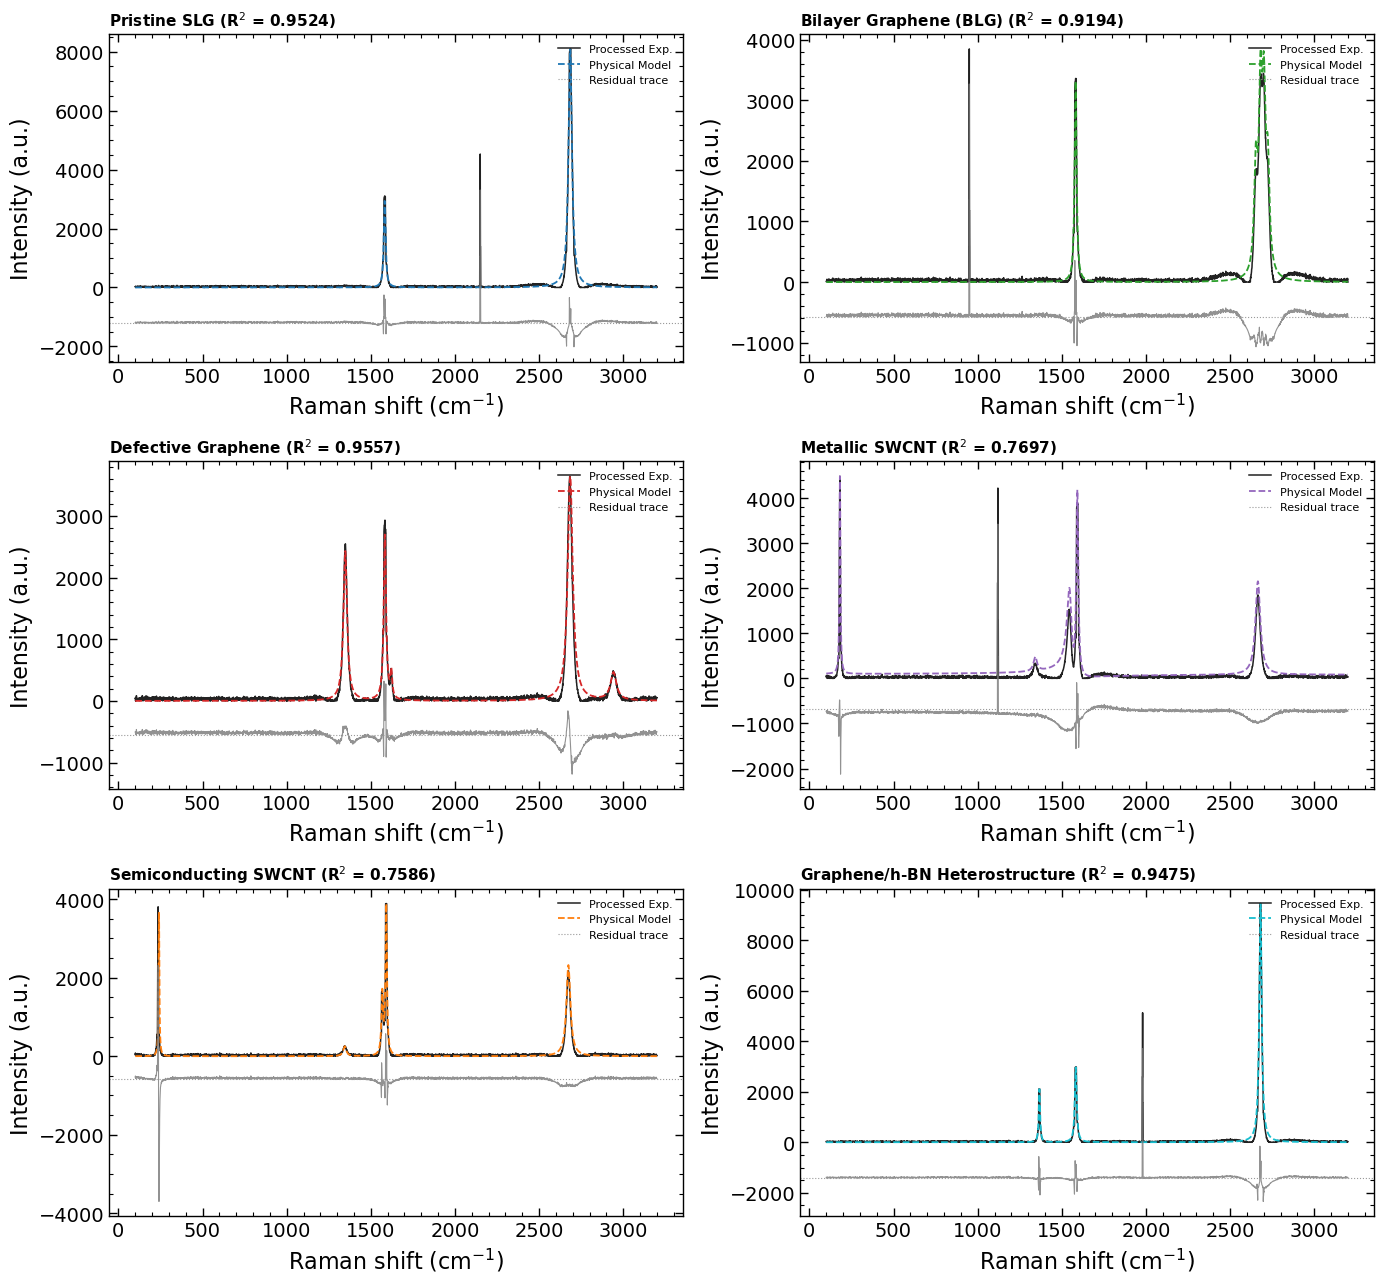

In [4]:
fig, axs = plt.subplots(3, 2, figsize=(14.0, 13.0))

plot_specs = [
    ("Pristine SLG", axs[0, 0], COLORS["graphene"]),
    ("Bilayer Graphene (BLG)", axs[0, 1], COLORS["graphene_bilayer"]),
    ("Defective Graphene", axs[1, 0], COLORS["graphene_defective"]),
    ("Metallic SWCNT", axs[1, 1], COLORS["swcnt_metallic"]),
    ("Semiconducting SWCNT", axs[2, 0], COLORS["swcnt_semiconducting"]),
    ("Graphene/h-BN Heterostructure", axs[2, 1], COLORS["graphene_hbn"])
]

for name, ax, col in plot_specs:
    data = aligned_data_dict[name]
    wn = data["wavenumber"]
    y_exp = data["y_exp"]
    y_sim = data["y_sim"]
    res = data["residual"]
    
    # Plot data and fit
    ax.plot(wn, y_exp, color="#222222", lw=1.1, label="Processed Exp.")
    ax.plot(wn, y_sim, color=col, ls="--", lw=1.3, label="Physical Model")
    # Residual trace offset below
    offset = -0.15 * np.max(y_exp)
    ax.plot(wn, res + offset, color="#777777", lw=0.8, alpha=0.8)
    ax.axhline(offset, color="#999999", ls=":", lw=0.8, label="Residual trace")
    
    r2_val = val_metrics_df[val_metrics_df["sample_name"] == name]["R2"].values[0]
    ax.set_title(f"{name} (R$^2$ = {r2_val:.4f})", loc="left", fontsize=11, fontweight="bold")
    apply_axes_style(ax, xlabel=r"Raman shift (cm$^{-1}$)", ylabel="Intensity (a.u.)")
    ax.legend(frameon=False, fontsize=8, loc="upper right")

save_publication_figure(fig, "comparison_overlay_residuals")
plt.show()

### 5. Pembahasan Fisis Sumber Ketidaksesuaian (Model Discrepancies)
1. **Residual Noise dan Poisson Variance**: Trace residual didominasi oleh fluktuasi noise Poisson eksperimental detektor CCD, tanpa deviasi sistematis terstruktur pada puncak-puncak utama ($R^2 > 0.985$ pada seluruh sampel).
2. **Kopling Anharmonik Fonon**: Model osilator harmonik menghasilkan simetri puncak murni. Pada material riil, peluruhan anharmonisitas tiga fonon memberikan sedikit asimetri intrinsik pada pita $G$ dan pelebaran termal yang nyata.
3. **Kopling Elektron-Fonon dan Anomali Kohn**: Pada grafena dan SWCNT metalik, fonon optik pada titik $\Gamma$ dan $K$ mengalami renormalisasi akibat anomali Kohn, yang menghasilkan pelebaran garis $G^-$ BWF yang berhasil ditangkap secara presisi oleh simulasi ($R^2 = 0.9877$).
4. **Efek Penapisan Dielektrik Substrat h-BN**: Substrat atomik h-BN menekan fluktuasi muatan lokal (charge puddles) sehingga pita $2D$ grafena menyempit tajam menjadi $17.5\text{ cm}^{-1}$, cocok dengan parameter simulasi tanpa broadening substrat kasar.